In [203]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from sklearn import preprocessing


df = pd.read_csv('US Fed New 1.2.csv')

df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df = df.sort_values('Date')#, ascending=False)

print(df['Date'].head())

scaler = preprocessing.MinMaxScaler()
scaled_data =scaler.fit_transform(df[['Balance sheet', 'UST 10', 'SP PE']])

#convert the Numpy array back to a DataFrame
scaled_df = pd.DataFrame(scaled_data, columns=['Balance sheet', 'UST 10', 'SP PE']) 


#log_data = np.log(df[['Balance sheet', 'Interest rate', 'UST 10', 'SP PE']])


from statsmodels.tsa.stattools import adfuller

def check_stationarity(series, name):
    result = adfuller(series)
    print(f"ADF Statistic for {name}: {result[0]}")
    print(f"p-value for {name}: {result[1]}")
    if result[1] <= 0.05:
        print(f"{name} is stationary")
    else:
        print(f"{name} is non-stationary")

check_stationarity(scaled_df['Balance sheet'], 'Balance sheet')
check_stationarity(scaled_df['UST 10'], 'UST 10 years')    
check_stationarity(scaled_df['SP PE'], 'S&P 500 PE')

# check_stationarity(log_data['Balance sheet'], 'Balance sheet')
# check_stationarity(log_data['Interest rate'], 'Interest rate')   
# check_stationarity(df['UST 10'], 'US 10-Year Treasury Yield')     
# check_stationarity(log_data['SP PE'], 'S&P 500 PE')


0   2007-06-29
1   2007-09-28
2   2007-12-31
3   2008-03-31
4   2008-06-30
Name: Date, dtype: datetime64[ns]
ADF Statistic for Balance sheet: nan
p-value for Balance sheet: nan
Balance sheet is non-stationary
ADF Statistic for UST 10 years: nan
p-value for UST 10 years: nan
UST 10 years is non-stationary
ADF Statistic for S&P 500 PE: nan
p-value for S&P 500 PE: nan
S&P 500 PE is non-stationary


In [204]:
# Differencing Non-Stationary Series
df_diff = scaled_df.copy()
df_diff['Balance_sheet_diff'] = df_diff['Balance sheet'].diff()
#df_diff['Interest_rate_diff'] = df_diff['Interest rate'].diff()
df_diff['UST_10_diff'] = df_diff['UST 10'].diff()
df_diff['SP_PE_diff'] = df_diff['SP PE'].diff()

# Retain interest rate as-is since it's stationary
#df_diff['Interest_rate'] = df_diff['Interest rate']

#Drop NA rows after differencing
df_diff = df_diff.dropna(subset=['Balance_sheet_diff', 'SP_PE_diff', 'UST_10_diff'])


new_stationary = check_stationarity(df_diff['Balance_sheet_diff'], 'Balance sheet')
new_stationary = check_stationarity(df_diff['SP_PE_diff'], 'S&P 500 PE')
new_stationary = check_stationarity(df_diff['UST_10_diff'], 'US 10-Year Treasury Yield (Differenced)')
#new_stationary = check_stationarity(df_diff['Interest_rate_diff'], 'Interest rate')

#df_diff['Interest_rate_diff'] = df_diff['Interest rate'].diff()
#new_stationary = check_stationarity(df_diff['Interest_rate_diff'], 'Interest rate')

ADF Statistic for Balance sheet: -4.847446613878553
p-value for Balance sheet: 4.40901984505257e-05
Balance sheet is stationary
ADF Statistic for S&P 500 PE: -3.082728523813403
p-value for S&P 500 PE: 0.02785803995653544
S&P 500 PE is stationary
ADF Statistic for US 10-Year Treasury Yield (Differenced): -4.15005563553314
p-value for US 10-Year Treasury Yield (Differenced): 0.0007995944500068551
US 10-Year Treasury Yield (Differenced) is stationary


In [205]:
# Calculate min/max of differenced series before scaling
# original_diff = df[['Balance sheet', 'SP PE']].diff().dropna()
# balance_sheet_diff_min = original_diff['Balance sheet'].min()
# balance_sheet_diff_max = original_diff['Balance sheet'].max()
# sp_pe_diff_min = original_diff['SP PE'].min()
# sp_pe_diff_max = original_diff['SP PE'].max()

# print("\nDifferenced Data Ranges (Original Scale):")
# print(f"Balance_sheet_diff: Min = {balance_sheet_diff_min}, Max = {balance_sheet_diff_max}")
# print(f"SP_PE_diff: Min = {sp_pe_diff_min}, Max = {sp_pe_diff_max}")
# range_sp_pe = sp_pe_diff_max - sp_pe_diff_min
# range_balance_sheet = balance_sheet_diff_max - balance_sheet_diff_min
# print(f"Range SP_PE_diff: {range_sp_pe}")
# print(f"Range Balance_sheet_diff: {range_balance_sheet}")

# # For interest rate (not differenced), get original min/max
# interest_min = df['Interest rate'].min()
# interest_max = df['Interest rate'].max()
# print(f"\nOriginal Interest Rate Range: Min = {interest_min}, Max = {interest_max}")
# ====== END OF ADDED CODE ======

# import pandas as pd

# # Load the dataset
# df = pd.read_csv('US Fed New 1.csv')

# # Calculate the standard deviation for the "Balance sheet" column
# balance_sheet_std = df['Balance sheet'].diff().std()
# interest_rate_std = df['Interest rate'].std()
# sp_pe_std = df["SP PE"].diff().std()

# print(f"The calculated standard deviation Balance sheet: {balance_sheet_std}")
# print(f"The calculated standard deviation Interest rate: {interest_rate_std}")
# print(f"The calculated standard deviation Interest rate: {sp_pe_std}")

                            OLS Regression Results                            
Dep. Variable:                  SP PE   R-squared:                       0.615
Model:                            OLS   Adj. R-squared:                  0.608
Method:                 Least Squares   F-statistic:                     89.44
Date:                Tue, 29 Jul 2025   Prob (F-statistic):           3.32e-13
Time:                        05:16:04   Log-Likelihood:                 37.513
No. Observations:                  58   AIC:                            -71.03
Df Residuals:                      56   BIC:                            -66.91
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.0675      0.033      2.062

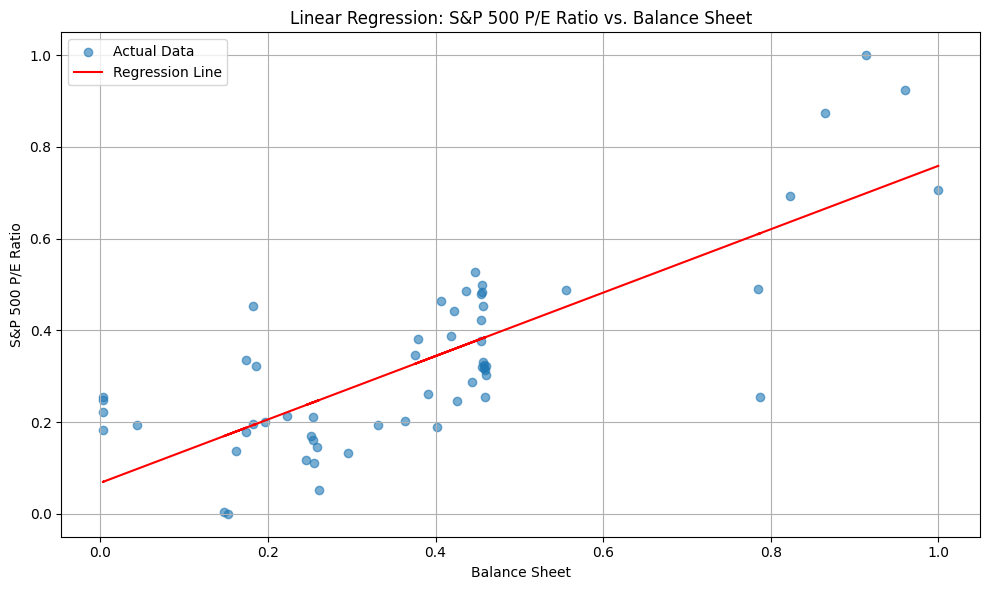

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Tue, 29, Jul, 2025
Time:                     05:16:04
--------------------------------------------------------------------
No. of Equations:         3.00000    BIC:                   -15.9787
Nobs:                     57.0000    HQIC:                  -16.2416
Log likelihood:           237.012    FPE:                7.48272e-08
AIC:                     -16.4088    Det(Omega_mle):     6.10512e-08
--------------------------------------------------------------------
Results for equation Balance sheet
                      coefficient       std. error           t-stat            prob
-----------------------------------------------------------------------------------
const                    0.081104         0.037479            2.164           0.030
L1.Balance sheet         0.873026         0.072366           12.064           0.000
L1.SP PE                 0.099273       

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)


In [228]:
import statsmodels.api as sm

X = df_diff[['Balance sheet']]
y = df_diff['SP PE']
X = sm.add_constant(X)


model = sm.OLS(y, X).fit()
print(model.summary())
print(model.pvalues)

# Create scatter plot with regression line
plt.figure(figsize=(10, 6))
plt.scatter(df_diff['Balance sheet'], df_diff['SP PE'], alpha=0.6, label='Actual Data')
plt.plot(df_diff['Balance sheet'], model.predict(X), color='red', label='Regression Line')
plt.xlabel('Balance Sheet')
plt.ylabel('S&P 500 P/E Ratio')
plt.title('Linear Regression: S&P 500 P/E Ratio vs. Balance Sheet')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

import statsmodels.tsa.api as smt

data = df_diff[['Balance sheet', 'SP PE', 'UST 10']]

model = smt.VAR(data).fit()
print(model.summary())
print(model.pvalues)


import statsmodels.api as sm
import pandas as pd # Assuming df_diff is a pandas DataFrame
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

# Assuming df_diff is already defined with 'Balance sheet', 'Interest rate', and 'SP PE'
# X = df_diff[['Balance sheet', 'Interest rate']]
# y = df_diff['SP PE']
# X = sm.add_constant(X)
# model = sm.OLS(y, X).fit()

# For anova_lm, it's often more convenient to use the formula API
# It also handles adding the constant automatically
formula = 'Q("SP PE") ~ Q("Balance sheet") + Q("UST 10")'
# Use Q() to handle column names with spaces
# Or, if your column names don't have spaces, you can use:
# formula = 'SP_PE ~ Balance_sheet + Interest_rate' 
# after renaming your columns in df_diff if necessary

model_formula = ols(formula, data=df_diff).fit()

# Get the ANOVA table
anova_table = anova_lm(model_formula, typ=2) # typ=2 is a common choice for balanced designs

print("\nANOVA Table:")
print(anova_table)

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)


 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -16.35     -16.23*   7.956e-08      -16.30
1      -16.67      -16.21   5.786e-08     -16.49*
2      -16.60      -15.80   6.220e-08      -16.29
3      -16.54      -15.39   6.669e-08      -16.10
4      -16.66      -15.17   6.012e-08      -16.10
5     -16.85*      -15.01  5.177e-08*      -16.15
6      -16.76      -14.58   5.955e-08      -15.93
7      -16.72      -14.20   6.629e-08      -15.76
8      -16.58      -13.71   8.495e-08      -15.48
-------------------------------------------------
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Mon, 28, Jul, 2025
Time:                     15:31:27
--------------------------------------------------------------------
No. of Equations:         3.00000    BIC:                   -14.4190
Nobs:                     53.0000    

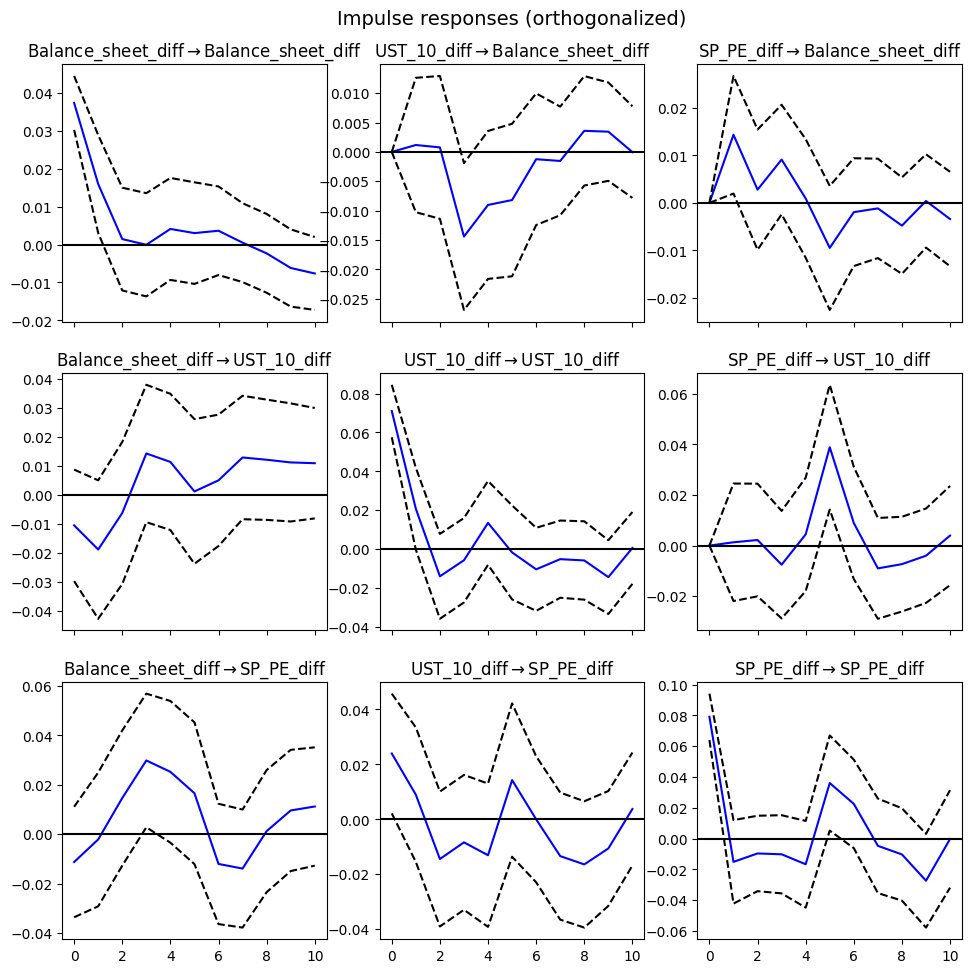

In [226]:
#VAR input dataset
df_var = df_diff[['Balance_sheet_diff', 'UST_10_diff', 'SP_PE_diff']]

from statsmodels.tsa.api import VAR

model_var = VAR(df_var)
results_select_order = model_var.select_order(maxlags=8)
print(results_select_order.summary())

# Refit VAR model with optimal lag order
optimal_lag = results_select_order.selected_orders['aic']
results = model_var.fit(maxlags=optimal_lag)
print(results.summary())

for eq in results.params.index:
    print(f"\nEquation for {eq}:")
    coeffs = results.params.loc[eq]
    for var, coeff in coeffs.items():
        print(f"  {var}: {coeff:.4f}")

'''model_var = VAR(df_var)
results = model_var.fit(maxlags=8, ic='bic')
#results = model_var.fit(autolag='AIC', ic='aic') # salah...dalam var.fit() takleh ada autolag
results.summary()

results.plot()
#results.plot_forecast(10)'''

irf = results.irf(10)
irf.plot(orth=True)


#plt.tight_layout()

plt.show()

In [208]:
# === Simple code to get and print IRF values ===
irf_values = irf.irfs
#results.irf(10)
print("\nQuantified IRF Values (Array):")
print(irf_values)



Quantified IRF Values (Array):
[[[ 1.00000000e+00  0.00000000e+00  0.00000000e+00]
  [ 0.00000000e+00  1.00000000e+00  0.00000000e+00]
  [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]

 [[ 4.69559315e-01 -4.44412095e-02  1.81243814e-01]
  [-4.17522633e-01  2.85953227e-01  1.65147939e-02]
  [-6.10334866e-02  1.90473488e-01 -1.91403498e-01]]

 [[ 4.88565733e-02 -9.90213650e-04  3.52142612e-02]
  [-2.14927541e-01 -2.07878801e-01  2.79306756e-02]
  [ 3.09737063e-01 -1.62212644e-01 -1.22244879e-01]]

 [[-3.46989977e-02 -2.41821723e-01  1.15288552e-01]
  [ 3.41457716e-01 -4.98149410e-02 -9.52080132e-02]
  [ 7.39159981e-01 -7.45749238e-02 -1.29125449e-01]]

 [[ 7.70299423e-02 -1.31133989e-01  1.17570177e-02]
  [ 3.70340081e-01  1.69794589e-01  5.59527335e-02]
  [ 5.80595648e-01 -1.12868690e-01 -2.11099874e-01]]

 [[ 2.36455418e-02 -7.50256198e-02 -1.19811658e-01]
  [ 1.28308539e-01 -1.90825336e-01  4.91436927e-01]
  [ 5.94614105e-01  4.71128853e-02  4.56165818e-01]]

 [[ 8.73135304e-02 -

In [209]:
# === 2️⃣ Define variable names and horizon range ===
variables = ['Balance_sheet_diff', 'Interest_rate_diff', 'SP_PE_diff']
horizons = np.arange(irf_values.shape[0])


In [210]:
# === 3️⃣ Build a tidy DataFrame ===
records = []
for h in horizons:
    for i, response in enumerate(variables):
        for j, impulse in enumerate(variables):
            records.append({
                'Horizon': h,
                'Impulse': impulse,
                'Response': response,
                'Value': irf_values[h, i, j]
            })

irf_df = pd.DataFrame(records)

# === Define impulse-response pairs to keep ===
# selected_pairs = [
#     ('Balance_sheet_diff', 'SP_PE_diff'),
#     ('Balance_sheet_diff', 'Interest_rate')
# ]

# === Filter IRF DataFrame ===
# filtered_df = irf_df[
#     irf_df.apply(lambda row: (row['Impulse'], row['Response']) in selected_pairs, axis=1)
# ]



In [211]:
print("\n✅ Filtered IRF DataFrame Preview:")
print(irf_df.head(20))


✅ Filtered IRF DataFrame Preview:
    Horizon             Impulse            Response     Value
0         0  Balance_sheet_diff  Balance_sheet_diff  1.000000
1         0  Interest_rate_diff  Balance_sheet_diff  0.000000
2         0          SP_PE_diff  Balance_sheet_diff  0.000000
3         0  Balance_sheet_diff  Interest_rate_diff  0.000000
4         0  Interest_rate_diff  Interest_rate_diff  1.000000
5         0          SP_PE_diff  Interest_rate_diff  0.000000
6         0  Balance_sheet_diff          SP_PE_diff  0.000000
7         0  Interest_rate_diff          SP_PE_diff  0.000000
8         0          SP_PE_diff          SP_PE_diff  1.000000
9         1  Balance_sheet_diff  Balance_sheet_diff  0.469559
10        1  Interest_rate_diff  Balance_sheet_diff -0.044441
11        1          SP_PE_diff  Balance_sheet_diff  0.181244
12        1  Balance_sheet_diff  Interest_rate_diff -0.417523
13        1  Interest_rate_diff  Interest_rate_diff  0.285953
14        1          SP_PE_diff  In

In [212]:
# === 5️⃣ Save to CSV ===
irf_df.to_csv('Filtered_IRF_Results.csv', index=False)
print("\n✅ Filtered IRF values saved to 'Filtered_IRF_Results.csv'!")


✅ Filtered IRF values saved to 'Filtered_IRF_Results.csv'!


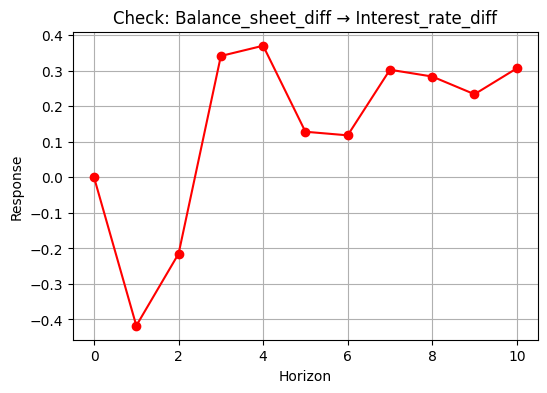

In [213]:
import matplotlib.pyplot as plt

subset = irf_df[(irf_df['Impulse'] == 'Balance_sheet_diff') &
                 (irf_df['Response'] == 'Interest_rate_diff')]

plt.figure(figsize=(6,4))
plt.plot(subset['Horizon'], subset['Value'], 'o-', color='red')
plt.title('Check: Balance_sheet_diff → Interest_rate_diff')
plt.xlabel('Horizon')
plt.ylabel('Response')
plt.grid()
plt.show()



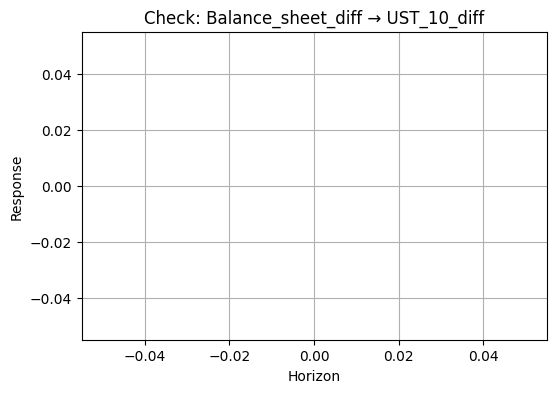

In [214]:
import matplotlib.pyplot as plt

subset = irf_df[(irf_df['Impulse'] == 'Balance_sheet_diff') &
                 (irf_df['Response'] == 'UST_10_diff')]

plt.figure(figsize=(6,4))
plt.plot(subset['Horizon'], subset['Value'], 'o-', color='red')
plt.title('Check: Balance_sheet_diff → UST_10_diff')
plt.xlabel('Horizon')
plt.ylabel('Response')
plt.grid()
plt.show()

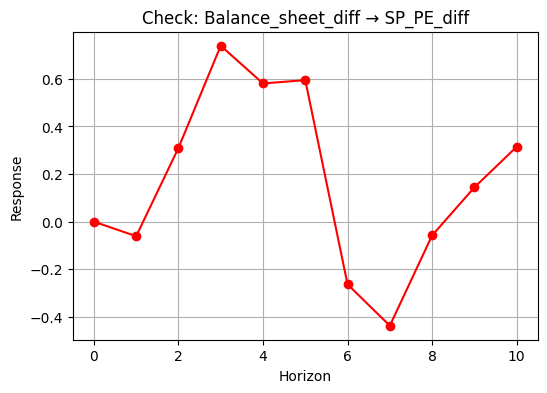

In [215]:
import matplotlib.pyplot as plt

subset = irf_df[(irf_df['Impulse'] == 'Balance_sheet_diff') &
                 (irf_df['Response'] == 'SP_PE_diff')]

plt.figure(figsize=(6,4))
plt.plot(subset['Horizon'], subset['Value'], 'o-', color='red')
plt.title('Check: Balance_sheet_diff → SP_PE_diff')
plt.xlabel('Horizon')
plt.ylabel('Response')
plt.grid()
plt.show()

In [216]:
# Use your ORIGINAL DataFrame 'df' before any scaling
sp_pe_min = df['SP PE'].min()
sp_pe_max = df['SP PE'].max()

interest_max = df['Interest rate'].max()
interest_min = df['Interest rate'].min()

# Calculate the range
sp_pe_range = sp_pe_max - sp_pe_min
interest_range = interest_max - interest_min

print(f"Original S&P P/E Min: {sp_pe_min}")
print(f"Original S&P P/E Max: {sp_pe_max}")
print(f"Original S&P P/E Range: {sp_pe_range}")

print(f"Original Interest rate Min: {interest_min}")
print(f"Original Interest rate Max: {interest_max}")
print(f"Original Interest rate Range: {interest_range}")

Original S&P P/E Min: 11.6392
Original S&P P/E Max: 31.2682
Original S&P P/E Range: 19.628999999999998
Original Interest rate Min: 0.25
Original Interest rate Max: 5.25
Original Interest rate Range: 5.0


In [217]:
# Get last value of each column
last_balance_sheet = df["Balance sheet"].iloc[-1]
last_interest_rate = df["Interest rate"].iloc[-1]
last_sp_pe = df["SP PE"].iloc[-1]

print("Last Balance Sheet value:", last_balance_sheet)
print("Last Interest Rate value:", last_interest_rate)
print("Last SP PE value:", last_sp_pe)

Last Balance Sheet value: nan
Last Interest Rate value: nan
Last SP PE value: nan


In [218]:

# Calculate 1 S.D. of residuals (your shock size)
residuals = results.resid
print("1 Standard Deviation of Residuals:")
print(residuals.std())

# For orthogonalized IRFs (Cholesky decomposition):
orth_shocks = np.linalg.cholesky(results.sigma_u)  # Sigma_u = covariance matrix
print("\n1 S.D. Orthogonalized Shocks:")
print(np.diag(orth_shocks))

1 Standard Deviation of Residuals:
Balance_sheet_diff    0.031516
UST_10_diff           0.060565
SP_PE_diff            0.070379
dtype: float64

1 S.D. Orthogonalized Shocks:
[0.03736262 0.0710374  0.07913062]


Roots of the characteristic polynomial:
[-1.94115633+1.60909249j -1.94115633-1.60909249j -0.33010034+2.10081557j
 -0.33010034-2.10081557j -1.23244815-0.j         -0.87938006+0.82990527j
 -0.87938006-0.82990527j  0.80407125-0.88892317j  0.80407125+0.88892317j
 -0.20627057-1.12785069j -0.20627057+1.12785069j  1.04443785-0.37853067j
  1.04443785+0.37853067j  0.49811749-0.97060794j  0.49811749+0.97060794j]

Stability condition:
All roots < 1? False


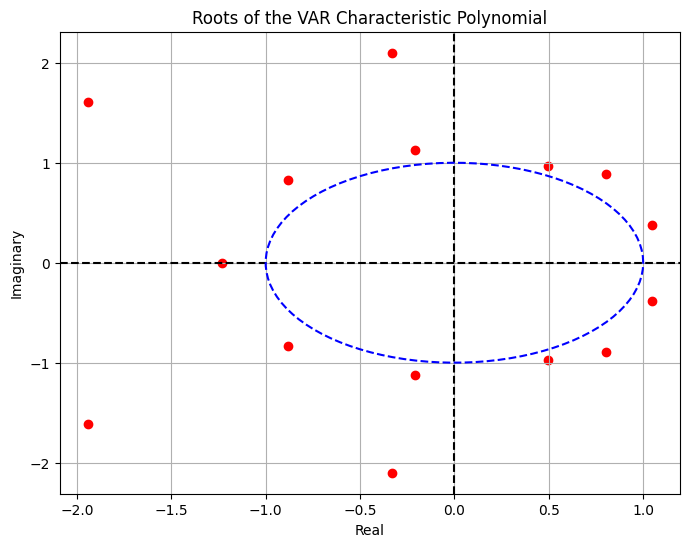

In [219]:
# After fitting your VAR model (results = model.fit())
roots = results.roots
print("Roots of the characteristic polynomial:")
print(roots)

# Check if all roots are within the unit circle
print("\nStability condition:")
print(f"All roots < 1? {np.all(np.abs(roots) < 1)}")

# Plot the roots
plt.figure(figsize=(8, 6))
plt.scatter(np.real(roots), np.imag(roots), marker='o', color='red')
plt.axhline(0, color='black', linestyle='--')
plt.axvline(0, color='black', linestyle='--')
plt.grid(True)
plt.title("Roots of the VAR Characteristic Polynomial")
plt.xlabel("Real")
plt.ylabel("Imaginary")

# Add unit circle for reference
theta = np.linspace(0, 2*np.pi, 100)
plt.plot(np.cos(theta), np.sin(theta), color='blue', linestyle='--')
plt.show()

In [220]:
# import seaborn as sns

# # Plot Balance Sheet response to a Balance Sheet shock
# balance_shock = irf_real[
#     (irf_real['Impulse'] == 'Balance_sheet_diff') & 
#     (irf_real['Response'] == 'Balance_sheet_diff')
# ]
# plt.figure(figsize=(10, 4))
# sns.lineplot(data=balance_shock, x='Horizon', y='Value_real')
# plt.title("Real-World Impact of Balance Sheet Shock (in $)")
# plt.ylabel("Change in Balance Sheet")
# plt.show()

# Compare distributions
# import seaborn as sns

# # Original vs Log vs Scaled
# fig, axes = plt.subplots(3, 3, figsize=(15, 10))
# for i, col in enumerate(['Balance sheet', 'Interest rate', 'SP PE']):
#     # Original
#     sns.histplot(df[col], ax=axes[0,i], kde=True)
#     axes[0,i].set_title(f"Original {col}")
    
#     # Log (where applicable)
#     if (df[col] > 0).all():
#         sns.histplot(np.log(df[col]), ax=axes[1,i], kde=True)
#         axes[1,i].set_title(f"Log {col}")
#     else:
#         axes[1,i].text(0.5, 0.5, "Cannot log-transform", ha='center')
    
#     # MinMax Scaled
#     scaler = preprocessing.MinMaxScaler()
#     scaled = scaler.fit_transform(df[[col]])
#     sns.histplot(scaled, ax=axes[2,i], kde=True)
#     axes[2,i].set_title(f"Scaled {col}")
# plt.tight_layout()